# 24 — Diagnostic Assets for the Final Model

Diabetic Foot Plantar Thermography — Physics-Informed GAT Project

## Why This Notebook Exists

Several standard paper figures were never built for the **current, final** headline
model. The PR curve, calibration curve, and confusion matrix currently exist only for
earlier, now-superseded models (from Phases 11/13/14), either because they predate the
final model or because the underlying data was never saved — per-epoch training history
was computed during every CV / multi-seed / ablation training run across this project,
but discarded after each notebook finished; only final checkpoints and summary metrics
survived.

This notebook produces exactly the missing pieces, all for the **current final model**
(`results/final_model_predictions.csv`, Phase 24's 3-way fusion + CV-threshold polish):

1. One representative training curve, via a single, cheap, additive retrain of fold 0
2. A 3-way confusion matrix comparison (TCI-alone / DualBranchGAT-alone / final fusion)
3. A precision-recall curve
4. A calibration curve

No existing checkpoint, split file, or prior result file is modified anywhere in this
notebook. The fold-0 retrain writes to a **new** checkpoint path
(`checkpoints/diagnostic_fold0_best.pt`) and never touches Phase 13's
`checkpoints/cv_fold0_best.pt`.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import confusion_matrix, precision_recall_curve, average_precision_score

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.dataset import PlantarThermographyDataset
from src.model import DualBranchGAT
from src.train import build_model, train_model

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"=== SETUP: Device ===")
print(f"Using device: {DEVICE}")

DATA_DIR = Path('data/processed')
RESULTS_DIR = Path('results')
FIGURES_DIR = RESULTS_DIR / 'figures'
CHECKPOINTS_DIR = Path('checkpoints')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)

# Consistent with the project's established color convention (02_eda.ipynb onward)
CONTROL_COLOR = '#1f77b4'
DM_COLOR = '#ff7f0e'
GAT_COLOR = '#2ca02c'

=== SETUP: Device ===
Using device: cuda


## Section 1: Setup

Load `subject_metadata.csv`, `graph_manifest.csv`, `normalization_stats.json`, and the
three prediction files.

**Note on `split_manifest.csv`:** `PlantarThermographyDataset` (Phase 7's spec) needs
both the image-branch paths (`raw_array_path` / `relative_array_path` /
`colormap_png_path`, which live in `split_manifest.csv`) and the graph-branch path
(`npz_path`, which lives in `graph_manifest.csv`) merged together on
`['subject_id', 'foot_side']` — `graph_manifest.csv` alone carries no image paths. This
notebook therefore also reads `split_manifest.csv` and rebuilds the same
`combined_manifest_df` merge Phase 7 and Phase 13 used, even though it wasn't called
out as a separate item in the file list above; PRIMARY_CONFIG here uses
`use_image_branch=True`, so the image paths are required, not optional.

In [2]:
print("=== SECTION 1: Loading Source Files ===")

subject_metadata_df = pd.read_csv(DATA_DIR / 'subject_metadata.csv')
graph_manifest_df = pd.read_csv(DATA_DIR / 'graph_manifest.csv')
split_manifest_df = pd.read_csv(DATA_DIR / 'split_manifest.csv')
with open(DATA_DIR / 'normalization_stats.json') as f:
    normalization_stats = json.load(f)

final_model_predictions_df = pd.read_csv(RESULTS_DIR / 'final_model_predictions.csv')
cv_pooled_predictions_df = pd.read_csv(RESULTS_DIR / 'cv_pooled_predictions.csv')
baseline_pooled_predictions_df = pd.read_csv(RESULTS_DIR / 'baseline_pooled_predictions.csv')

print(f"subject_metadata_df:            {subject_metadata_df.shape}")
print(f"graph_manifest_df:              {graph_manifest_df.shape}")
print(f"split_manifest_df:              {split_manifest_df.shape}")
print(f"final_model_predictions_df:     {final_model_predictions_df.shape}")
print(f"cv_pooled_predictions_df:       {cv_pooled_predictions_df.shape}")
print(f"baseline_pooled_predictions_df: {baseline_pooled_predictions_df.shape}")

# Combined image+graph manifest, same merge as Phase 7 / Phase 13
combined_manifest_df = split_manifest_df.merge(
    graph_manifest_df[['subject_id', 'foot_side', 'npz_path']],
    on=['subject_id', 'foot_side'],
    how='inner',
)
print(f"combined_manifest_df (image + graph paths merged): {combined_manifest_df.shape}")
assert combined_manifest_df.shape[0] == 334, (
    f"Expected 334 rows (167 subjects x 2 feet) in combined_manifest_df, "
    f"got {combined_manifest_df.shape[0]}"
)
print("combined_manifest_df row count: PASS (334/334)")

=== SECTION 1: Loading Source Files ===
subject_metadata_df:            (167, 19)
graph_manifest_df:              (334, 9)
split_manifest_df:              (334, 15)
final_model_predictions_df:     (167, 7)
cv_pooled_predictions_df:       (167, 6)
baseline_pooled_predictions_df: (167, 7)
combined_manifest_df (image + graph paths merged): (334, 16)
combined_manifest_df row count: PASS (334/334)


In [3]:
print()
print("=== SECTION 1: Merging the 3 Prediction Files ===")

working_df = final_model_predictions_df[
    ['subject_id', 'group', 'true_label', 'fold', 'final_model_prob', 'pred_label_cv_threshold']
].copy()

working_df = working_df.merge(
    cv_pooled_predictions_df[['subject_id', 'true_label', 'mc_mean_prob', 'pred_label_optimal']].rename(
        columns={'true_label': 'true_label_cv', 'mc_mean_prob': 'gat_prob'}
    ),
    on='subject_id', how='inner',
)

working_df = working_df.merge(
    baseline_pooled_predictions_df[['subject_id', 'true_label', 'LR_worse_foot_tci']].rename(
        columns={'true_label': 'true_label_baseline', 'LR_worse_foot_tci': 'tci_prob'}
    ),
    on='subject_id', how='inner',
)

n_rows = working_df.shape[0]
rows_pass = (n_rows == 167)
print(f"Merged working_df shape: {working_df.shape}")
print(f"Row count check: {'PASS' if rows_pass else 'FAIL'} ({n_rows}/167 rows)")

label_agreement = (
    (working_df['true_label'] == working_df['true_label_cv']).all()
    and (working_df['true_label'] == working_df['true_label_baseline']).all()
)
print(f"true_label agreement across all 3 source files: {'PASS' if label_agreement else 'FAIL'}")

assert rows_pass, f"Expected 167 merged rows, got {n_rows}"
assert label_agreement, "true_label mismatch across the 3 source prediction files"

working_df = working_df.drop(columns=['true_label_cv', 'true_label_baseline'])
working_df = working_df[
    ['subject_id', 'group', 'true_label', 'fold', 'final_model_prob',
     'pred_label_cv_threshold', 'gat_prob', 'pred_label_optimal', 'tci_prob']
]

print()
print(working_df.head())


=== SECTION 1: Merging the 3 Prediction Files ===
Merged working_df shape: (167, 11)
Row count check: PASS (167/167 rows)
true_label agreement across all 3 source files: PASS

  subject_id    group  true_label  fold  final_model_prob  \
0      CG007  Control           0     0          0.278435   
1      CG009  Control           0     0          0.309351   
2      CG010  Control           0     0          0.299114   
3      CG011  Control           0     0          0.271929   
4      CG024  Control           0     0          0.332573   

   pred_label_cv_threshold  gat_prob  pred_label_optimal  tci_prob  
0                        0  0.214824                   0  0.127307  
1                        0  0.191896                   0  0.230497  
2                        0  0.178642                   0  0.198440  
3                        0  0.237222                   0  0.109968  
4                        0  0.363434                   1  0.141110  


## Section 2: Reproduce Fold 0 Exactly

Rebuild fold 0's train/val/test subject split using the identical method Phase 13
(`12_cross_validation.ipynb`) used: `StratifiedKFold(n_splits=5, shuffle=True,
random_state=42)` on `Group`, take the first fold, then split that fold's non-test
subjects 90/10 (stratified, `random_state=42`) into train/val. This fold's test subjects
are not touched anywhere in this notebook — only train/val are used below, since the
goal here is one representative training curve, not a fresh test evaluation.

In [4]:
print("=== SECTION 2: Reproducing Fold 0 Exactly (Phase 13's Method) ===")

subject_ids_all = subject_metadata_df['Subject'].values
groups_all = subject_metadata_df['Group'].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
folds = list(skf.split(subject_ids_all, groups_all))

fold0_train_val_idx, fold0_test_idx = folds[0]
fold0_train_val_subjects = subject_ids_all[fold0_train_val_idx]
fold0_train_val_groups = groups_all[fold0_train_val_idx]
fold0_test_subjects = subject_ids_all[fold0_test_idx]

fold0_train_subjects, fold0_val_subjects = train_test_split(
    fold0_train_val_subjects,
    test_size=0.10,
    stratify=fold0_train_val_groups,
    random_state=RANDOM_SEED,
)

print(f"Fold 0 sizes -- train: {len(fold0_train_subjects)}, "
      f"val: {len(fold0_val_subjects)}, test: {len(fold0_test_subjects)}")
print("Expected (Phase 13): train~119, val~14, test~34")

=== SECTION 2: Reproducing Fold 0 Exactly (Phase 13's Method) ===
Fold 0 sizes -- train: 119, val: 14, test: 34
Expected (Phase 13): train~119, val~14, test~34


## Section 3: Retrain Fold 0 With Full History Capture

Every prior CV / multi-seed / ablation notebook called `train_model()` and only kept the
returned `best_epoch` / `best_val_roc_auc` — the full per-epoch `history` list was always
discarded once the notebook finished. This section reruns fold 0's exact training
procedure (same `PRIMARY_CONFIG` and hyperparameters as Phases 10/13) purely to capture
that history, saving to a **new**, additive checkpoint path so Phase 13's original
`cv_fold0_best.pt` is left untouched.

In [5]:
print("=== SECTION 3: Retrain Fold 0 With Full History Capture ===")

def build_fold_loader(subject_list, manifest_df, norm_stats, batch_size=16, shuffle=False):
    subset_df = manifest_df[manifest_df['subject_id'].isin(subject_list)].reset_index(drop=True)
    dataset = PlantarThermographyDataset(subset_df, norm_stats)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)
    return dataset, loader

fold0_train_dataset, fold0_train_loader = build_fold_loader(
    fold0_train_subjects, combined_manifest_df, normalization_stats, batch_size=16, shuffle=True
)
fold0_val_dataset, fold0_val_loader = build_fold_loader(
    fold0_val_subjects, combined_manifest_df, normalization_stats, batch_size=16, shuffle=False
)

print(f"Fold 0 train dataset (feet): {len(fold0_train_dataset)}")
print(f"Fold 0 val dataset (feet):   {len(fold0_val_dataset)}")

fold0_train_groups_series = subject_metadata_df[
    subject_metadata_df['Subject'].isin(fold0_train_subjects)
]['Group']
n_train = len(fold0_train_groups_series)
n_control = int((fold0_train_groups_series == 'Control').sum())
n_dm = int((fold0_train_groups_series == 'DM').sum())
weight_control = n_train / (2 * n_control)
weight_dm = n_train / (2 * n_dm)

print(f"Fold 0 train class counts -- Control: {n_control}, DM: {n_dm}")
print(f"Fold 0 class weights -- Control: {weight_control:.4f}, DM: {weight_dm:.4f}")
print("Using DM's own (smaller) weight as pos_weight, downweighting the majority "
      "class -- same reasoning as Phase 10.")

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight_dm))

PRIMARY_CONFIG = {
    'use_graph_branch': True,
    'use_image_branch': True,
    'graph_topology': 'base',
    'image_key': 'colormap_image',
    'image_in_channels': 3,
}

CHECKPOINT_PATH = 'checkpoints/diagnostic_fold0_best.pt'  # new, additive -- does NOT overwrite cv_fold0_best.pt

history, best_epoch, best_val_roc_auc = train_model(
    PRIMARY_CONFIG,
    fold0_train_loader,
    fold0_val_loader,
    criterion,
    DEVICE,
    max_epochs=150,
    patience=20,
    lr=1e-3,
    weight_decay=1e-4,
    checkpoint_path=CHECKPOINT_PATH,
)

print()
print(f"Fold 0 retrain complete -- best_epoch: {best_epoch}, best_val_roc_auc: {best_val_roc_auc:.4f}")
print(f"Total epochs recorded in history: {len(history)}")

=== SECTION 3: Retrain Fold 0 With Full History Capture ===
Fold 0 train dataset (feet): 238
Fold 0 val dataset (feet):   28
Fold 0 train class counts -- Control: 32, DM: 87
Fold 0 class weights -- Control: 1.8594, DM: 0.6839
Using DM's own (smaller) weight as pos_weight, downweighting the majority class -- same reasoning as Phase 10.
epoch    0 | train_loss=0.4815 val_loss=0.4716 val_roc_auc=0.7062 val_bal_acc=0.6125 *
epoch    3 | train_loss=0.3301 val_loss=0.5278 val_roc_auc=0.7125 val_bal_acc=0.6000 *
epoch    4 | train_loss=0.3205 val_loss=0.4838 val_roc_auc=0.7437 val_bal_acc=0.6000 *
epoch    5 | train_loss=0.3076 val_loss=0.4597 val_roc_auc=0.7437 val_bal_acc=0.6000
epoch    7 | train_loss=0.2984 val_loss=0.4685 val_roc_auc=0.7625 val_bal_acc=0.5750 *
epoch    8 | train_loss=0.3174 val_loss=0.4502 val_roc_auc=0.7875 val_bal_acc=0.5750 *
epoch    9 | train_loss=0.3108 val_loss=0.4212 val_roc_auc=0.8125 val_bal_acc=0.6500 *
epoch   10 | train_loss=0.3019 val_loss=0.4208 val_roc_a

## Section 4: Save and Plot the Training Curve

**Caveat — read before interpreting this plot:** this is ONE representative fold (fold 0
of the primary 5-fold CV), not every training run in this project. It is included to
demonstrate stable convergence behavior, not as a performance claim — the project's
actual reported metrics come from the pooled CV / fusion results (Phases 13–24), not
this single fold.

=== SECTION 4: Save and Plot the Training Curve ===
Saved 49-epoch history to results/training_history_fold0.json


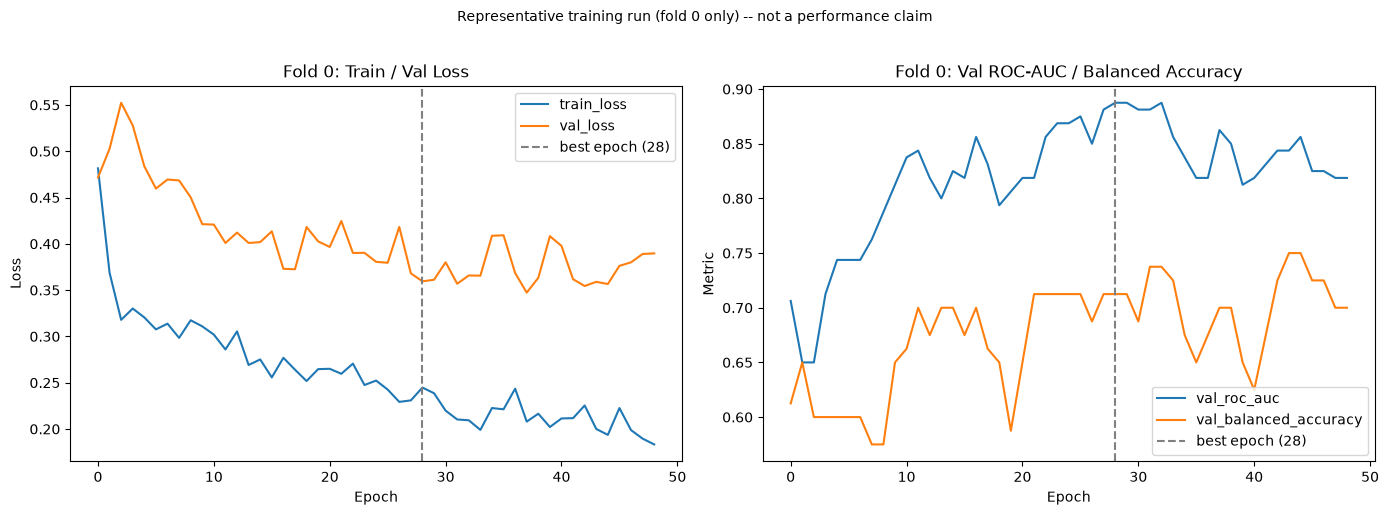

Saved results/figures/fig5_training_curve.png


In [6]:
print("=== SECTION 4: Save and Plot the Training Curve ===")

with open(RESULTS_DIR / 'training_history_fold0.json', 'w') as f:
    json.dump(history, f, indent=2, default=float)
print(f"Saved {len(history)}-epoch history to results/training_history_fold0.json")

epochs = [h['epoch'] for h in history]
train_loss = [h['train_loss'] for h in history]
val_loss = [h['val_loss'] for h in history]
val_roc_auc_hist = [h['val_roc_auc'] for h in history]
val_balanced_accuracy_hist = [h['val_balanced_accuracy'] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, train_loss, label='train_loss', color=CONTROL_COLOR)
axes[0].plot(epochs, val_loss, label='val_loss', color=DM_COLOR)
axes[0].axvline(best_epoch, color='gray', linestyle='--', label=f'best epoch ({best_epoch})')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Fold 0: Train / Val Loss')
axes[0].legend()

axes[1].plot(epochs, val_roc_auc_hist, label='val_roc_auc', color=CONTROL_COLOR)
axes[1].plot(epochs, val_balanced_accuracy_hist, label='val_balanced_accuracy', color=DM_COLOR)
axes[1].axvline(best_epoch, color='gray', linestyle='--', label=f'best epoch ({best_epoch})')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Metric')
axes[1].set_title('Fold 0: Val ROC-AUC / Balanced Accuracy')
axes[1].legend()

fig.suptitle('Representative training run (fold 0 only) -- not a performance claim', fontsize=10, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig5_training_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved results/figures/fig5_training_curve.png")

## Section 5: Confusion Matrix Comparison (3 Panels)

Compare TCI-alone (flat 0.5 cutoff, consistent with how baselines have been thresholded
throughout this project since Phase 15), DualBranchGAT-alone (its own per-fold CV
threshold, from the already-saved `pred_label_optimal` column), and the final fusion
model (Phase 24's CV-derived threshold, from the already-saved `pred_label_cv_threshold`
column). All three hard predictions already exist on disk — this section only computes
and visualizes the confusion matrices, it does not re-threshold anything.

=== SECTION 5: Confusion Matrix Comparison (3 Panels) ===


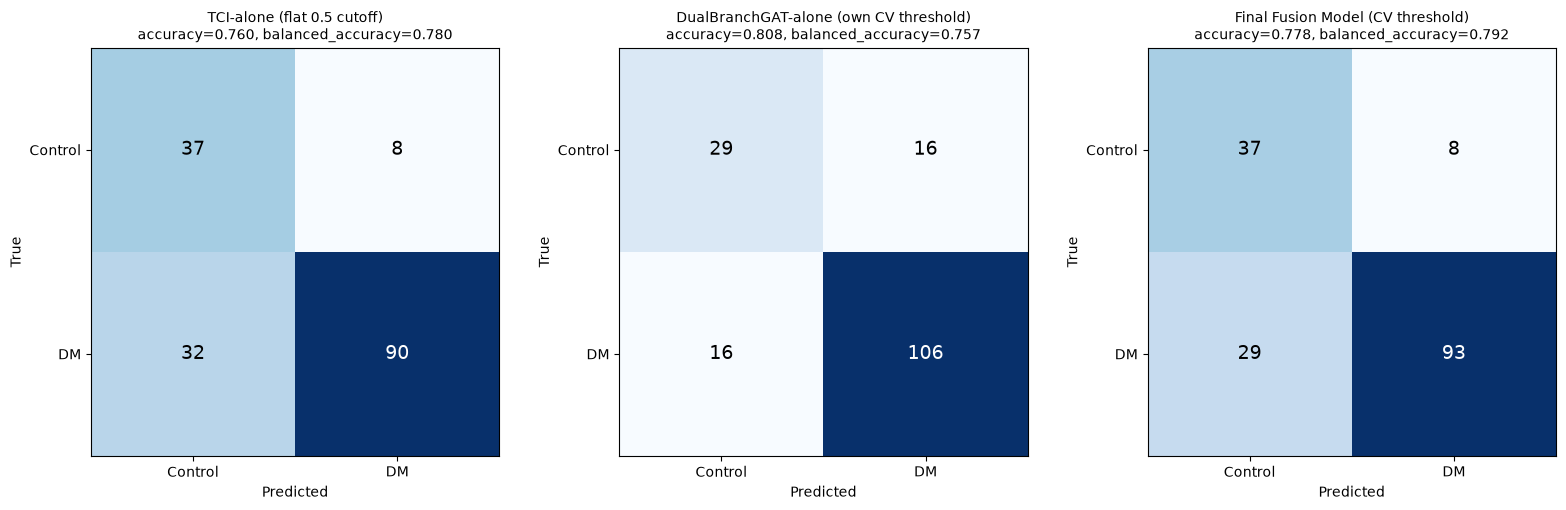

TCI-alone:      accuracy=0.7605, balanced_accuracy=0.7800
GAT-alone:      accuracy=0.8084, balanced_accuracy=0.7566
Fusion (final): accuracy=0.7784, balanced_accuracy=0.7923
Saved results/figures/fig6_confusion_matrices.png


In [7]:
print("=== SECTION 5: Confusion Matrix Comparison (3 Panels) ===")

tci_pred_05 = (working_df['tci_prob'] >= 0.5).astype(int)
gat_pred_optimal = working_df['pred_label_optimal'].astype(int)
fusion_pred_cv = working_df['pred_label_cv_threshold'].astype(int)
true_labels = working_df['true_label'].astype(int)


def cm_and_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    balanced_accuracy = (sensitivity + specificity) / 2
    return cm, accuracy, balanced_accuracy


cm_tci, acc_tci, bal_acc_tci = cm_and_metrics(true_labels, tci_pred_05)
cm_gat, acc_gat, bal_acc_gat = cm_and_metrics(true_labels, gat_pred_optimal)
cm_fusion, acc_fusion, bal_acc_fusion = cm_and_metrics(true_labels, fusion_pred_cv)

panels = [
    ('TCI-alone (flat 0.5 cutoff)', cm_tci, acc_tci, bal_acc_tci),
    ('DualBranchGAT-alone (own CV threshold)', cm_gat, acc_gat, bal_acc_gat),
    ('Final Fusion Model (CV threshold)', cm_fusion, acc_fusion, bal_acc_fusion),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (title, cm, acc, bal_acc) in zip(axes, panels):
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Control', 'DM'])
    ax.set_yticklabels(['Control', 'DM'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f"{title}\naccuracy={acc:.3f}, balanced_accuracy={bal_acc:.3f}", fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig6_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"TCI-alone:      accuracy={acc_tci:.4f}, balanced_accuracy={bal_acc_tci:.4f}")
print(f"GAT-alone:      accuracy={acc_gat:.4f}, balanced_accuracy={bal_acc_gat:.4f}")
print(f"Fusion (final): accuracy={acc_fusion:.4f}, balanced_accuracy={bal_acc_fusion:.4f}")
print("Saved results/figures/fig6_confusion_matrices.png")

## Section 6: Precision-Recall Curve for the Final Model

PR-AUC is more informative than ROC-AUC given this dataset's 73.05% DM prevalence
(Phase 15) — a random classifier's expected PR-AUC equals that prevalence, not 0.5, so
the no-skill reference line below is drawn at 0.7305, consistent with Phase 15.

=== SECTION 6: Precision-Recall Curve for the Final Model ===


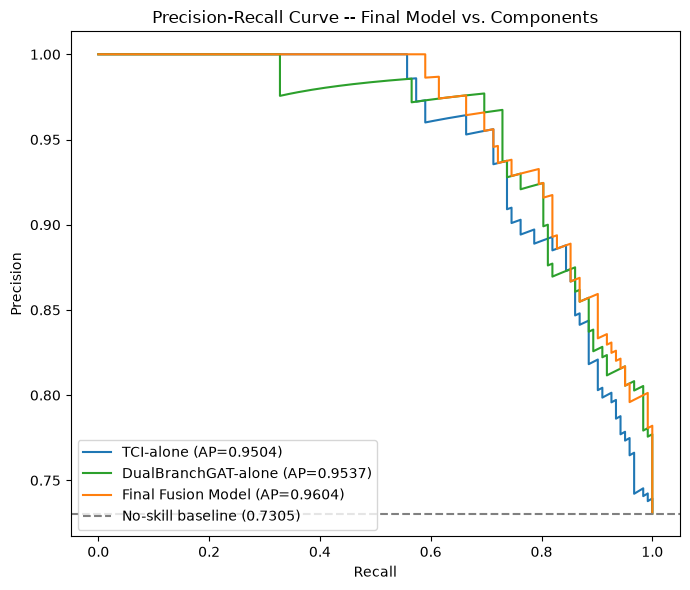

Average Precision (PR-AUC) -- TCI-alone:            0.9504
Average Precision (PR-AUC) -- DualBranchGAT-alone:  0.9537
Average Precision (PR-AUC) -- Final Fusion Model:   0.9604
Saved results/figures/fig7_pr_curve.png


In [8]:
print("=== SECTION 6: Precision-Recall Curve for the Final Model ===")

DM_PREVALENCE = 0.7305  # Phase 15 finding: 122/167 DM subjects

precision_tci, recall_tci, _ = precision_recall_curve(working_df['true_label'], working_df['tci_prob'])
precision_gat, recall_gat, _ = precision_recall_curve(working_df['true_label'], working_df['gat_prob'])
precision_final, recall_final, _ = precision_recall_curve(working_df['true_label'], working_df['final_model_prob'])

ap_tci = average_precision_score(working_df['true_label'], working_df['tci_prob'])
ap_gat = average_precision_score(working_df['true_label'], working_df['gat_prob'])
ap_final = average_precision_score(working_df['true_label'], working_df['final_model_prob'])

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_tci, precision_tci, label=f'TCI-alone (AP={ap_tci:.4f})', color=CONTROL_COLOR)
ax.plot(recall_gat, precision_gat, label=f'DualBranchGAT-alone (AP={ap_gat:.4f})', color=GAT_COLOR)
ax.plot(recall_final, precision_final, label=f'Final Fusion Model (AP={ap_final:.4f})', color=DM_COLOR)
ax.axhline(DM_PREVALENCE, color='gray', linestyle='--', label=f'No-skill baseline ({DM_PREVALENCE:.4f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve -- Final Model vs. Components')
ax.legend(loc='lower left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig7_pr_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Average Precision (PR-AUC) -- TCI-alone:            {ap_tci:.4f}")
print(f"Average Precision (PR-AUC) -- DualBranchGAT-alone:  {ap_gat:.4f}")
print(f"Average Precision (PR-AUC) -- Final Fusion Model:   {ap_final:.4f}")
print("Saved results/figures/fig7_pr_curve.png")

## Section 7: Calibration Curve for the Final Model

Reliability diagram (8 bins, same method as Phase 15) for TCI-alone and the final fusion
model, plus Brier score for both (mean squared error between predicted probability and
true label — lower is better). `average_precision_score` / `confusion_matrix` /
`precision_recall_curve` are the only `sklearn.metrics` functions imported per this
notebook's dependency list, so Brier score and accuracy/balanced-accuracy above are
computed directly rather than via `sklearn.metrics.brier_score_loss` /
`accuracy_score` / `balanced_accuracy_score`.

=== SECTION 7: Calibration Curve for the Final Model ===


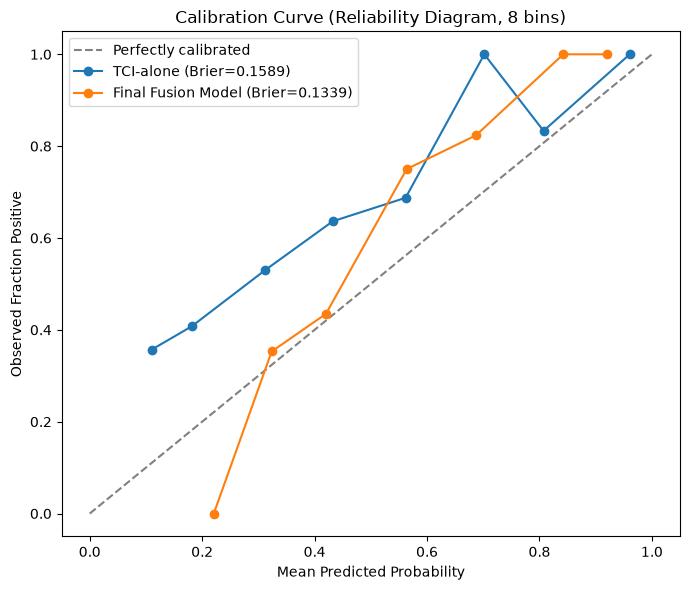

Brier score -- TCI-alone:          0.1589
Brier score -- Final Fusion Model: 0.1339
Saved results/figures/fig8_calibration.png


In [9]:
print("=== SECTION 7: Calibration Curve for the Final Model ===")

def reliability_diagram(y_true, probs, n_bins=8):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_indices = np.digitize(probs, bin_edges[1:-1])
    mean_predicted = []
    observed_fraction = []
    for b in range(n_bins):
        mask = bin_indices == b
        if mask.sum() > 0:
            mean_predicted.append(probs[mask].mean())
            observed_fraction.append(y_true[mask].mean())
    return np.array(mean_predicted), np.array(observed_fraction)


def brier_score(y_true, probs):
    return float(np.mean((probs - y_true) ** 2))


true_labels_arr = working_df['true_label'].values.astype(float)
tci_probs_arr = working_df['tci_prob'].values.astype(float)
final_probs_arr = working_df['final_model_prob'].values.astype(float)

mp_tci, of_tci = reliability_diagram(true_labels_arr, tci_probs_arr, n_bins=8)
mp_final, of_final = reliability_diagram(true_labels_arr, final_probs_arr, n_bins=8)

brier_tci = brier_score(true_labels_arr, tci_probs_arr)
brier_final = brier_score(true_labels_arr, final_probs_arr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
ax.plot(mp_tci, of_tci, marker='o', color=CONTROL_COLOR, label=f'TCI-alone (Brier={brier_tci:.4f})')
ax.plot(mp_final, of_final, marker='o', color=DM_COLOR, label=f'Final Fusion Model (Brier={brier_final:.4f})')
ax.set_xlabel('Mean Predicted Probability')
ax.set_ylabel('Observed Fraction Positive')
ax.set_title('Calibration Curve (Reliability Diagram, 8 bins)')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig8_calibration.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Brier score -- TCI-alone:          {brier_tci:.4f}")
print(f"Brier score -- Final Fusion Model: {brier_final:.4f}")
print("Saved results/figures/fig8_calibration.png")

## Section 8: Save Summary

Consolidate everything computed above into `results/diagnostic_assets_summary.json`.

In [10]:
print("=== SECTION 8: Save Summary ===")

diagnostic_assets_summary = {
    'fold0_best_epoch': int(best_epoch),
    'fold0_best_val_roc_auc': float(best_val_roc_auc),
    'confusion_matrices': {
        'tci_alone_0.5': {
            'cm': cm_tci.tolist(), 'accuracy': float(acc_tci), 'balanced_accuracy': float(bal_acc_tci),
        },
        'gat_alone_own_threshold': {
            'cm': cm_gat.tolist(), 'accuracy': float(acc_gat), 'balanced_accuracy': float(bal_acc_gat),
        },
        'final_fusion_cv_threshold': {
            'cm': cm_fusion.tolist(), 'accuracy': float(acc_fusion), 'balanced_accuracy': float(bal_acc_fusion),
        },
    },
    'pr_auc': {
        'tci_alone': float(ap_tci),
        'gat_alone': float(ap_gat),
        'final_fusion': float(ap_final),
    },
    'brier_scores': {
        'tci_alone': float(brier_tci),
        'final_fusion': float(brier_final),
    },
    'figures_saved': [
        'results/figures/fig5_training_curve.png',
        'results/figures/fig6_confusion_matrices.png',
        'results/figures/fig7_pr_curve.png',
        'results/figures/fig8_calibration.png',
    ],
}

with open(RESULTS_DIR / 'diagnostic_assets_summary.json', 'w') as f:
    json.dump(diagnostic_assets_summary, f, indent=2, default=float)

print("Saved results/diagnostic_assets_summary.json")

=== SECTION 8: Save Summary ===
Saved results/diagnostic_assets_summary.json


## Section 9: Final Summary

In [11]:
print("=== SECTION 9: Final Summary ===")

issues_found = []

print("Files saved this run:")
print("  - results/figures/fig5_training_curve.png")
print("  - results/figures/fig6_confusion_matrices.png")
print("  - results/figures/fig7_pr_curve.png")
print("  - results/figures/fig8_calibration.png")
print("  - results/training_history_fold0.json")
print("  - results/diagnostic_assets_summary.json")

print()
print(f"Fold 0 representative training run -- best epoch: {best_epoch}, "
      f"best val ROC-AUC: {best_val_roc_auc:.4f}")

print()
print("Final model (fusion, CV threshold) confusion matrix [rows=true, cols=pred, order=Control/DM]:")
print(cm_fusion)
print(f"Final model accuracy: {acc_fusion:.4f}, balanced_accuracy: {bal_acc_fusion:.4f}")
print(f"Final model PR-AUC:   {ap_final:.4f}")

print()
if issues_found:
    print(f"Issues found: {issues_found}")
else:
    print("0 issues found")

print()
print("Next step: Phase 26, the final consolidation notebook, which will pull these new")
print("figures together with everything from Phases 12-24.")

=== SECTION 9: Final Summary ===
Files saved this run:
  - results/figures/fig5_training_curve.png
  - results/figures/fig6_confusion_matrices.png
  - results/figures/fig7_pr_curve.png
  - results/figures/fig8_calibration.png
  - results/training_history_fold0.json
  - results/diagnostic_assets_summary.json

Fold 0 representative training run -- best epoch: 28, best val ROC-AUC: 0.8875

Final model (fusion, CV threshold) confusion matrix [rows=true, cols=pred, order=Control/DM]:
[[37  8]
 [29 93]]
Final model accuracy: 0.7784, balanced_accuracy: 0.7923
Final model PR-AUC:   0.9604

0 issues found

Next step: Phase 26, the final consolidation notebook, which will pull these new
figures together with everything from Phases 12-24.
